# Programme Title: Machine Learning CA1: Predicting Diabetes 	

**Module:** Machine Learning

**GitHub repository:** https://github.com/Ayabegim/Machine-Learning-CA1 

**Dataset:** `diabetes.csv`

**Domain:** Health

**Dataset:** Pima Indians Diabetes Database (768 patients, 8 features, 1 target). Source: Kaggle / UCI Machine Learning, originally from the US National Institute of Diabetes and Digestive and Kidney Diseases (Smith et al., 1988). Link: https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database

**Student name:** Aya Omirtay |  Student number:2026767

## 1. Setup and configuration

In [1]:
# --- Standard library
import time
import warnings

# --- Data handling and statistics
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm

# --- Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# --- scikit-learn
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_score, cross_validate, learning_curve,
                                     train_test_split, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore", category=FutureWarning)

# --- Configuration
DATA_PATH = r"C:\Users\Owner\Documents\Machine Learning\diabetes.csv"
TARGET = "Outcome"
RANDOM_STATE = 42
TEST_SPLITS = [0.05, 0.15, 0.25]   # share of patients held out for testing
TUNING_SPLIT = 0.25                # split used for GridSearchCV (Section 7)
CV_FOLDS = 10

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", None)
np.random.seed(RANDOM_STATE)
CLASS_NAMES = ["No diabetes", "Diabetes"]
PALETTE = {0: "#4c72b0", 1: "#dd8452"}

## 3. Characterisation of the data

### EDA Findings and Interpretation

The dataset contains 768 patient records and eight input features. The target variable is imbalanced: 65.1% of patients do not have diabetes, while 34.9% have diabetes. Therefore, accuracy alone may not provide a complete evaluation of model performance.

The correlation analysis shows that Glucose has the strongest positive correlation with the diabetes outcome (0.49), followed by BMI (0.31) and Insulin (0.30). The feature distribution plots also show differences between diabetic and non-diabetic patients, particularly for Glucose.

Although these relationships provide useful initial insights, correlation does not imply causation. Further machine learning analysis is required to evaluate the predictive contribution of each feature.

In [2]:
# --- Overview --- 
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print(f"Rows (patients): {df.shape[0]} | Columns: {df.shape[1]} (8 features + target)")
print(f"Duplicate rows:  {df.duplicated().sum()}")
print(f"Empty cells:     {df.isna().sum().sum()}")
print("\nData types:")
print(df.dtypes.to_string())
df.head()

Rows (patients): 768 | Columns: 9 (8 features + target)
Duplicate rows:  0
Empty cells:     0

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


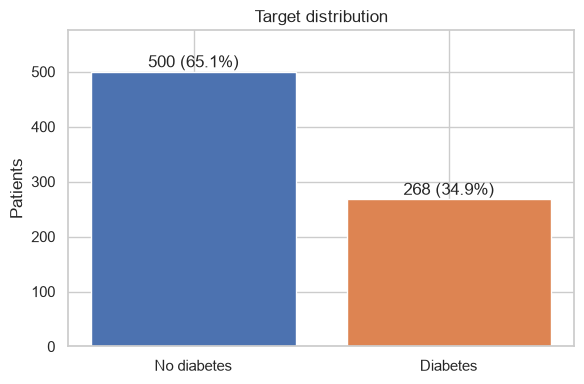

Majority-class baseline accuracy: 0.651


In [4]:
counts = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(CLASS_NAMES, counts.values, color=[PALETTE[0], PALETTE[1]])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 8, f"{v} ({v / len(df):.1%})", ha="center")
ax.set_ylabel("Patients"); ax.set_title("Target distribution"); ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout(); plt.show()
print(f"Majority-class baseline accuracy: {counts.max() / len(df):.3f}")

In [5]:
# Hidden missing values: zeros that cannot be real
ZERO_AS_MISSING = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_report = pd.DataFrame({
    "zeros": (df[ZERO_AS_MISSING] == 0).sum(),
    "percent": ((df[ZERO_AS_MISSING] == 0).mean() * 100).round(1),
})
zero_report

,zeros,percent
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4


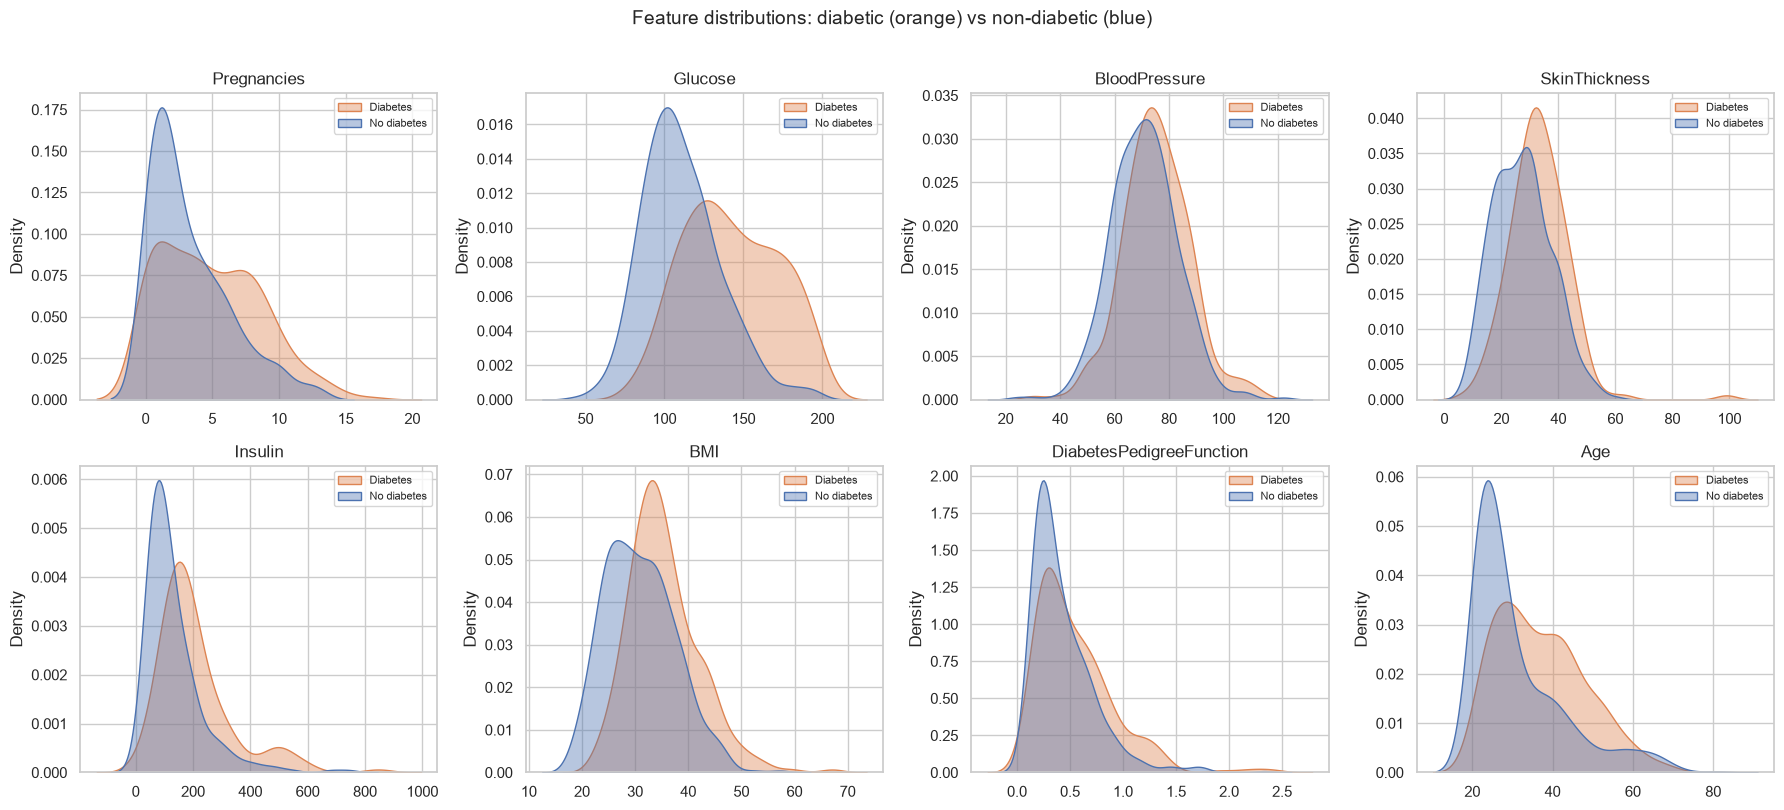

In [6]:
# Distributions by outcome
features = [c for c in df.columns if c != TARGET]
plot_df = df.copy()
plot_df[ZERO_AS_MISSING] = plot_df[ZERO_AS_MISSING].replace(0, np.nan)  # plot real values only

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, features):
    sns.kdeplot(data=plot_df, x=col, hue=TARGET, palette=PALETTE, fill=True,
                common_norm=False, alpha=0.4, ax=ax, warn_singular=False)
    ax.set_title(col); ax.set_xlabel("")
    ax.legend(title="", labels=CLASS_NAMES[::-1], fontsize=8)
fig.suptitle("Feature distributions: diabetic (orange) vs non-diabetic (blue)", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

In [ ]:
# --- Plot Correlation Matrix ---
fig, ax = plt.subplots(figsize=(8, 6))
corr = plot_df.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1), ax=ax)
ax.set_title("Correlation matrix (zeros treated as missing)")
plt.tight_layout(); plt.show()
print("Correlation of each feature with the outcome:")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_string())

## 4. Pre-processing

In [8]:
df[ZERO_AS_MISSING] = df[ZERO_AS_MISSING].replace(0, np.nan)
X = df.drop(columns=TARGET)
y = df[TARGET]
print(f"Final dataset: {X.shape[0]} rows x {X.shape[1]} features")
print("Missing values now flagged:")
print(X.isna().sum()[X.isna().sum() > 0].to_string())

Final dataset: 768 rows x 8 features
Missing values now flagged:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11


### Machine Learning Model Selection

Three classification algorithms were selected for this study: Logistic Regression, Random Forest and Support Vector Machine (SVM).

Logistic Regression was chosen as a baseline model because it is simple, interpretable and suitable for binary classification.

Random Forest was selected because it combines multiple decision trees and can capture non-linear relationships between features.

Support Vector Machine (SVM) was included because it can identify decision boundaries between the two outcome classes and is effective for classification tasks involving scaled numerical features.

Comparing these models allows their predictive performance and generalisation ability to be evaluated using the same dataset and validation approach.

## 5. Machine learning models and justification (Based on the instruction in Point a)

In [9]:
def make_pipeline(model):
    # Imputation and scaling are fitted inside each training fold only (no leakage)
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", model),
    ])

base_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "SVM (RBF)": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

## 6. Accuracy across the three splits with cross-validation

In [10]:
split_rows = []
for test_size in TEST_SPLITS:
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=test_size, stratify=y,
                                              random_state=RANDOM_STATE)
    for name, model in base_models.items():
        pipe = make_pipeline(clone(model))
        cv_scores = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="accuracy")
        pipe.fit(X_tr, y_tr)
        split_rows.append({
            "test split": f"{int(test_size * 100)}%", "model": name,
            "n_train": len(X_tr), "n_test": len(X_te),
            "cv_mean": cv_scores.mean(), "cv_std": cv_scores.std(),
            "train_acc": pipe.score(X_tr, y_tr), "test_acc": pipe.score(X_te, y_te),
        })

split_results = pd.DataFrame(split_rows)
split_results.round(3)

,test split,model,n_train,n_test,cv_mean,cv_std,train_acc,test_acc
0,5%,Logistic Regression,729,39,0.768,0.067,0.775,0.744
1,5%,Random Forest,729,39,0.759,0.056,1.000,0.795
2,5%,SVM (RBF),729,39,0.759,0.044,0.823,0.744
3,15%,Logistic Regression,652,116,0.773,0.037,0.785,0.707
4,15%,Random Forest,652,116,0.753,0.038,1.000,0.784
5,15%,SVM (RBF),652,116,0.767,0.054,0.830,0.741
6,25%,Logistic Regression,576,192,0.781,0.034,0.790,0.724
7,25%,Random Forest,576,192,0.759,0.054,1.000,0.745
8,25%,SVM (RBF),576,192,0.773,0.066,0.849,0.740


### Interpretation of Model Performance

The results show differences in predictive performance across the three test splits.

Random Forest achieved the highest test accuracy at the 5% and 15% splits (0.795 and 0.784, respectively). However, its training accuracy was 1.000 across all splits, suggesting possible overfitting.

Logistic Regression achieved the highest cross-validation mean accuracy at the 25% split (0.781), indicating consistent validation performance. SVM showed relatively stable test accuracy across all three splits, ranging from 0.740 to 0.744.

Overall, no single model performed best across every evaluation measure. Cross-validation results, test accuracy and the difference between training and test performance should all be considered when selecting the final model.

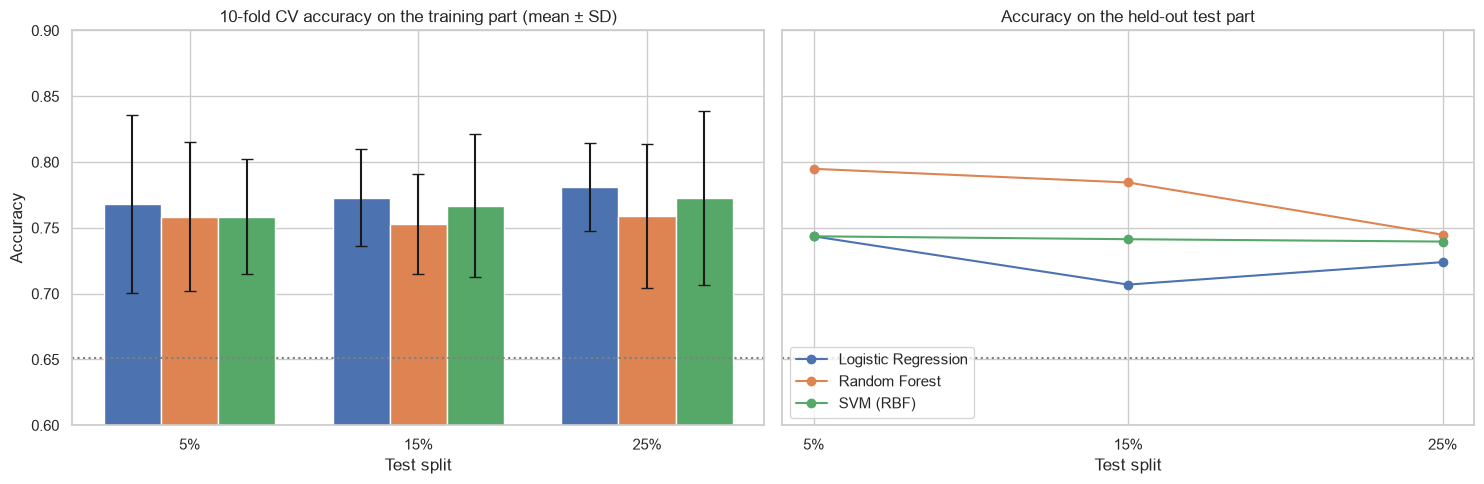

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
x = np.arange(len(TEST_SPLITS)); width = 0.25
for i, name in enumerate(base_models):
    sub = split_results[split_results["model"] == name]
    axes[0].bar(x + (i - 1) * width, sub["cv_mean"], width, yerr=sub["cv_std"], capsize=4, label=name)
    axes[1].plot(sub["test split"], sub["test_acc"], marker="o", label=name)
axes[0].set_xticks(x); axes[0].set_xticklabels([f"{int(s*100)}%" for s in TEST_SPLITS])
axes[0].set_title("10-fold CV accuracy on the training part (mean ± SD)")
axes[1].set_title("Accuracy on the held-out test part")
for ax in axes:
    ax.set_xlabel("Test split"); ax.set_ylim(0.6, 0.9)
    ax.axhline(y.value_counts(normalize=True).max(), ls=":", c="grey")
axes[0].set_ylabel("Accuracy"); axes[1].legend(loc="lower left")
plt.tight_layout(); plt.show()

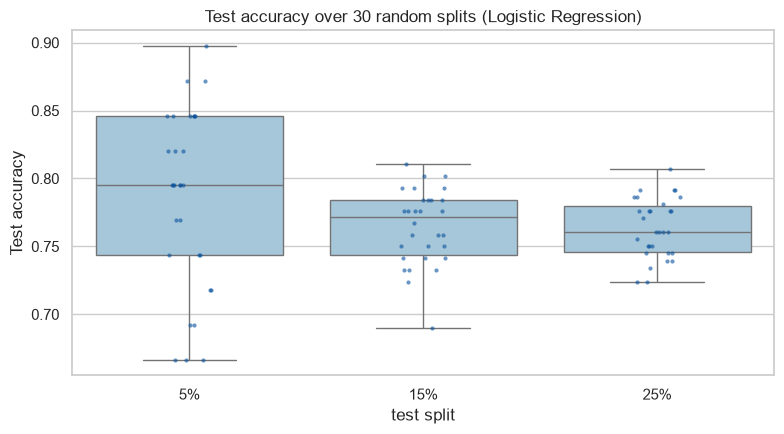

,mean,std,min,max
test split,,,,
5%,0.785,0.067,0.667,0.897
15%,0.765,0.028,0.690,0.810
25%,0.764,0.022,0.724,0.807


In [12]:
# As understood that the small test split will be unreliable which A single split can be lucky or unlucky. 
# To show how much the test score depends on which patients land in the test set, 
# the experiment below repeats every split 30 times with different random seeds (Logistic Regression, default settings).

repeat_rows = []
for test_size in TEST_SPLITS:
    for seed in range(30):
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=test_size, stratify=y, random_state=seed)
        acc = make_pipeline(LogisticRegression(max_iter=2000)).fit(X_tr, y_tr).score(X_te, y_te)
        repeat_rows.append({"test split": f"{int(test_size * 100)}%", "test_acc": acc})
repeats = pd.DataFrame(repeat_rows)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=repeats, x="test split", y="test_acc", color="#9ecae1", ax=ax)
sns.stripplot(data=repeats, x="test split", y="test_acc", color="#08519c", size=3, alpha=0.6, ax=ax)
ax.set_ylabel("Test accuracy"); ax.set_title("Test accuracy over 30 random splits (Logistic Regression)")
plt.tight_layout(); plt.show()
repeats.groupby("test split")["test_acc"].agg(["mean", "std", "min", "max"]).reindex(["5%", "15%", "25%"]).round(3)

## 7. Hyperparameter tuning (Based on instruction of point b)

In [13]:
# Technique will be used is "GridSearchCV"

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TUNING_SPLIT, stratify=y,
                                                    random_state=RANDOM_STATE)
print(f"Training: {len(X_train)} patients | Test: {len(X_test)} patients")

param_grids = {
    "Logistic Regression": {"model__C": [0.001, 0.01, 0.1, 1, 10, 100],
                            "model__class_weight": [None, "balanced"]},
    "Random Forest": {"model__n_estimators": [100, 300], "model__max_depth": [3, 5, 8, None],
                      "model__min_samples_leaf": [1, 5, 10], "model__max_features": ["sqrt", 0.5]},
    "SVM (RBF)": {"model__C": [0.1, 1, 10, 100], "model__gamma": ["scale", 0.001, 0.01, 0.1, 1]},
}

searches, tuning_rows = {}, []
for name, model in base_models.items():
    default_cv = cross_val_score(make_pipeline(clone(model)), X_train, y_train, cv=cv).mean()
    search = GridSearchCV(make_pipeline(clone(model)), param_grids[name], cv=cv,
                          scoring="accuracy", n_jobs=-1, return_train_score=True)
    t0 = time.perf_counter(); search.fit(X_train, y_train); secs = time.perf_counter() - t0
    searches[name] = search
    n_combos = len(search.cv_results_["params"])
    tuning_rows.append({
        "model": name, "combinations": n_combos, "fits": n_combos * CV_FOLDS,
        "default_cv_acc": default_cv, "tuned_cv_acc": search.best_score_,
        "improvement": search.best_score_ - default_cv,
        "tuned_test_acc": search.score(X_test, y_test),
        "best_params": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
        "seconds": secs,
    })

tuning_results = pd.DataFrame(tuning_rows).set_index("model")
tuning_results.round(3)

Training: 576 patients | Test: 192 patients


,combinations,fits,default_cv_acc,tuned_cv_acc,improvement,tuned_test_acc,best_params,seconds
model,,,,,,,,
Logistic Regression,12,120,0.781,0.781,0.000,0.729,"{'C': 0.1, 'class_weight': None}",8.554
Random Forest,48,480,0.759,0.771,0.012,0.714,"{'max_depth': 8, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 100}",99.971
SVM (RBF),20,200,0.773,0.781,0.009,0.708,"{'C': 100, 'gamma': 0.001}",6.974


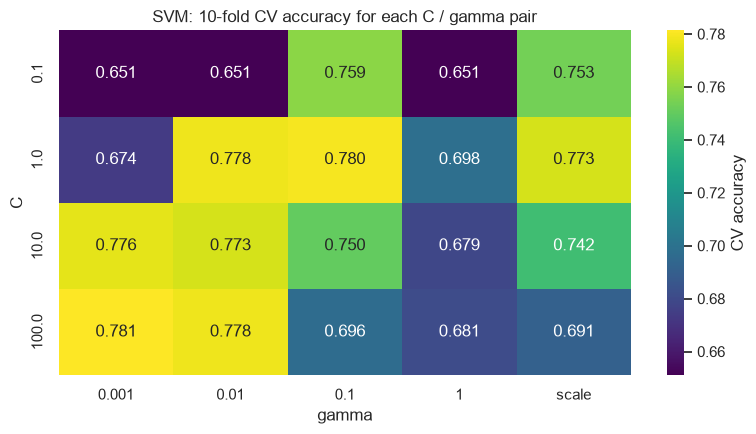

In [14]:
# How sensitive is the SVM to its two hyperparameters? (heatmap of mean CV accuracy)
svm_cv = pd.DataFrame(searches["SVM (RBF)"].cv_results_)
svm_cv["gamma"] = svm_cv["param_model__gamma"].astype(str)
grid = svm_cv.pivot_table(index="param_model__C", columns="gamma", values="mean_test_score")
grid = grid[["0.001", "0.01", "0.1", "1", "scale"]]

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(grid, annot=True, fmt=".3f", cmap="viridis", ax=ax, cbar_kws={"label": "CV accuracy"})
ax.set_xlabel("gamma"); ax.set_ylabel("C"); ax.set_title("SVM: 10-fold CV accuracy for each C / gamma pair")
plt.tight_layout(); plt.show()

## 8. Comparison and interpretation of the tuned models

In [15]:
# Performance on the held-out test set

# Accuracy is the main metric required by the brief. Because this is a medical screening problem, 
# Recall: The share of diabetic patients correctly identified) is also reported: 
# Missing a diabetic patient is usually more costly than a false alarm.

best_models = {name: s.best_estimator_ for name, s in searches.items()}
rows = []
for name, est in best_models.items():
    pred = est.predict(X_test); proba = est.predict_proba(X_test)[:, 1]
    rows.append({"model": name,
                 "train_acc": est.score(X_train, y_train),
                 "cv_acc": searches[name].best_score_,
                 "test_acc": accuracy_score(y_test, pred),
                 "precision": precision_score(y_test, pred),
                 "recall": recall_score(y_test, pred),
                 "f1": f1_score(y_test, pred),
                 "roc_auc": roc_auc_score(y_test, proba)})
comparison = pd.DataFrame(rows).set_index("model")
comparison["train-test gap"] = comparison["train_acc"] - comparison["test_acc"]
comparison.round(3)

,train_acc,cv_acc,test_acc,precision,recall,f1,roc_auc,train-test gap
model,,,,,,,,
Logistic Regression,0.788,0.781,0.729,0.636,0.522,0.574,0.823,0.059
Random Forest,0.964,0.771,0.714,0.600,0.537,0.567,0.806,0.250
SVM (RBF),0.786,0.781,0.708,0.604,0.478,0.533,0.824,0.078


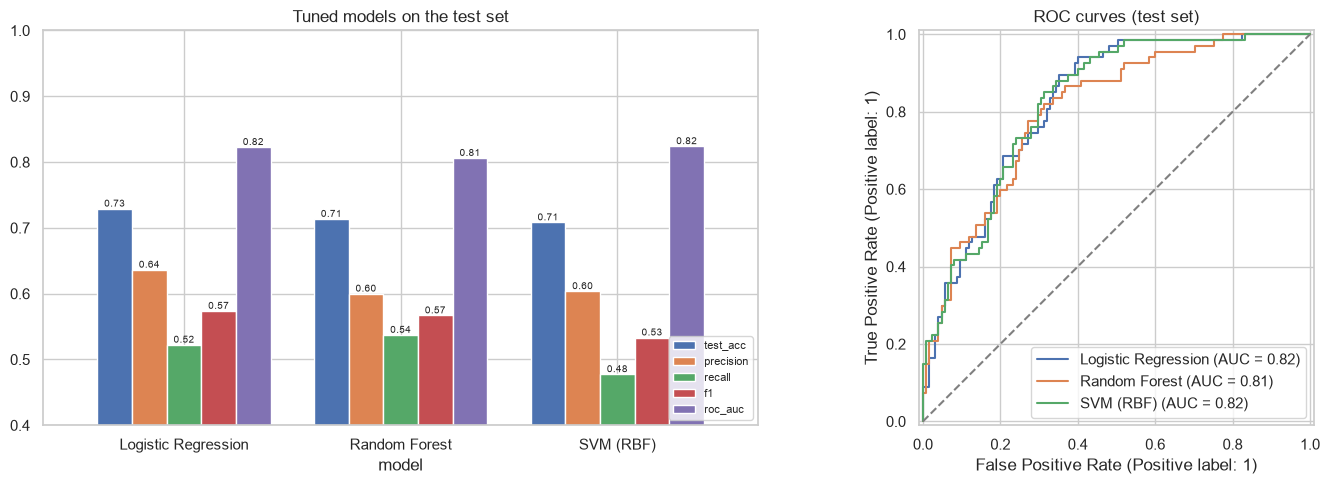

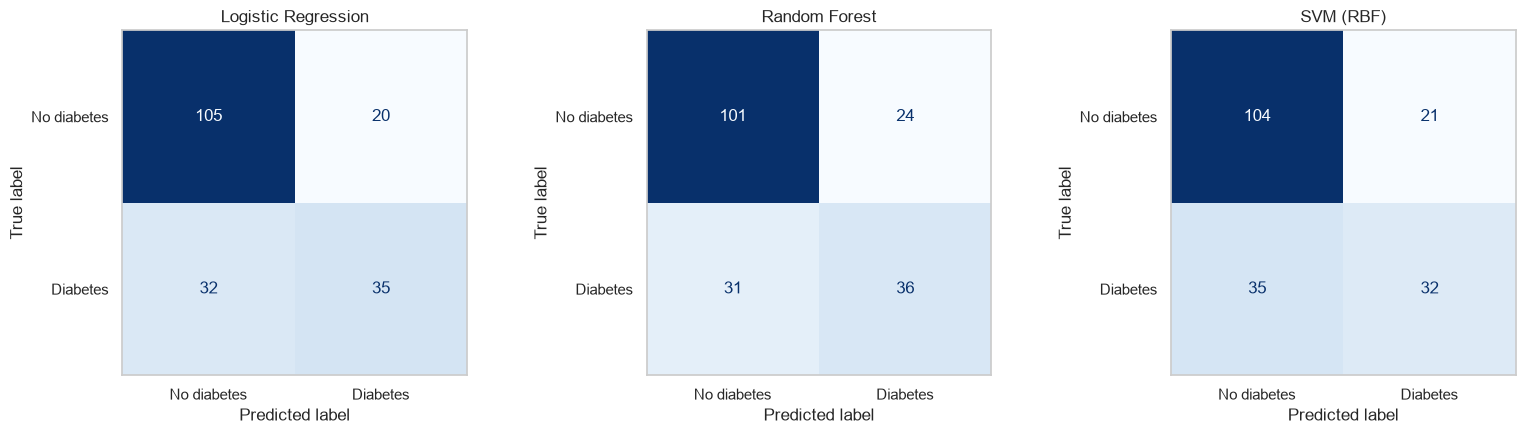

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
comparison[["test_acc", "precision", "recall", "f1", "roc_auc"]].plot.bar(ax=axes[0], rot=0, width=0.8)
axes[0].set_ylim(0.4, 1); axes[0].set_title("Tuned models on the test set"); axes[0].legend(loc="lower right", fontsize=8)
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.2f", fontsize=7)
for name, est in best_models.items():
    RocCurveDisplay.from_estimator(est, X_test, y_test, name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], ls="--", c="grey"); axes[1].set_title("ROC curves (test set)")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, est) in zip(axes, best_models.items()):
    ConfusionMatrixDisplay.from_estimator(est, X_test, y_test, display_labels=CLASS_NAMES,
                                          cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name); ax.grid(False)
plt.tight_layout(); plt.show()

In [17]:
# For screening, a missed diabetic patient matters more than a false alarm. 
# The models use a default cut-off of 0.5 probability. 
# Lowering the cut-off flags more patients: recall rises and precision falls. 
# The table shows this trade-off for the tuned Logistic Regression.

lr_proba = best_models["Logistic Regression"].predict_proba(X_test)[:, 1]
rows = []
for cut in [0.5, 0.4, 0.3, 0.2]:
    pred = (lr_proba >= cut).astype(int)
    rows.append({"cut-off": cut, "accuracy": accuracy_score(y_test, pred),
                 "recall": recall_score(y_test, pred), "precision": precision_score(y_test, pred),
                 "diabetic patients missed": int(((pred == 0) & (y_test == 1)).sum()),
                 "patients flagged": int(pred.sum())})
pd.DataFrame(rows).set_index("cut-off").round(3)

,accuracy,recall,precision,diabetic patients missed,patients flagged
cut-off,,,,,
0.5,0.729,0.522,0.636,32,55
0.4,0.740,0.627,0.627,25,67
0.3,0.714,0.761,0.567,16,90
0.2,0.708,0.896,0.550,7,109


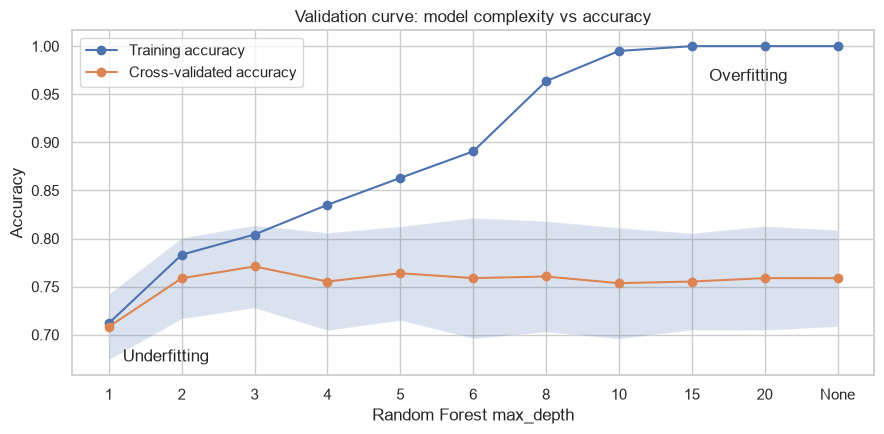

max_depth,1,2,3,4,5,6,8,10,15,20,None
train,0.712,0.783,0.804,0.835,0.863,0.891,0.964,0.995,1.000,1.000,1.000
cv,0.708,0.759,0.771,0.755,0.764,0.759,0.761,0.754,0.755,0.759,0.759
gap,0.004,0.024,0.033,0.080,0.099,0.132,0.203,0.241,0.245,0.241,0.241


In [18]:
# Overfitting, underfitting and generalisation

# Learning Noting: 
# Overfitting: the model memorises training patients; training accuracy is high but accuracy on new patients is much lower.
# Underfitting: the model is too simple; both training and test accuracy are low.
# Good generalisation: training and validation accuracy are close and both reasonably high.

# Two below diagnostic charts show this:
# Validation curve: Random Forest accuracy as tree depth increases, from very simple (depth 1) to unlimited.
# Learning curves: training and cross-validated accuracy as the amount of training data grows, for each tuned model.

depths = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, None]
depth_labels = [str(d) if d else "None" for d in depths]
rf_for_curve = make_pipeline(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))
train_sc, val_sc = validation_curve(rf_for_curve, X_train, y_train, param_name="model__max_depth",
                                    param_range=depths, cv=cv, scoring="accuracy", n_jobs=-1)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(depth_labels, train_sc.mean(axis=1), marker="o", label="Training accuracy")
ax.plot(depth_labels, val_sc.mean(axis=1), marker="o", label="Cross-validated accuracy")
ax.fill_between(depth_labels, val_sc.mean(1) - val_sc.std(1), val_sc.mean(1) + val_sc.std(1), alpha=0.2)
ax.annotate("Underfitting", (0, val_sc.mean(1)[0]), textcoords="offset points", xytext=(10, -25))
ax.annotate("Overfitting", (len(depths) - 2, train_sc.mean(1)[-2]), textcoords="offset points", xytext=(-40, -25))
ax.set_xlabel("Random Forest max_depth"); ax.set_ylabel("Accuracy"); ax.legend()
ax.set_title("Validation curve: model complexity vs accuracy")
plt.tight_layout(); plt.show()
pd.DataFrame({"max_depth": depth_labels, "train": train_sc.mean(1), "cv": val_sc.mean(1),
              "gap": train_sc.mean(1) - val_sc.mean(1)}).round(3).set_index("max_depth").T

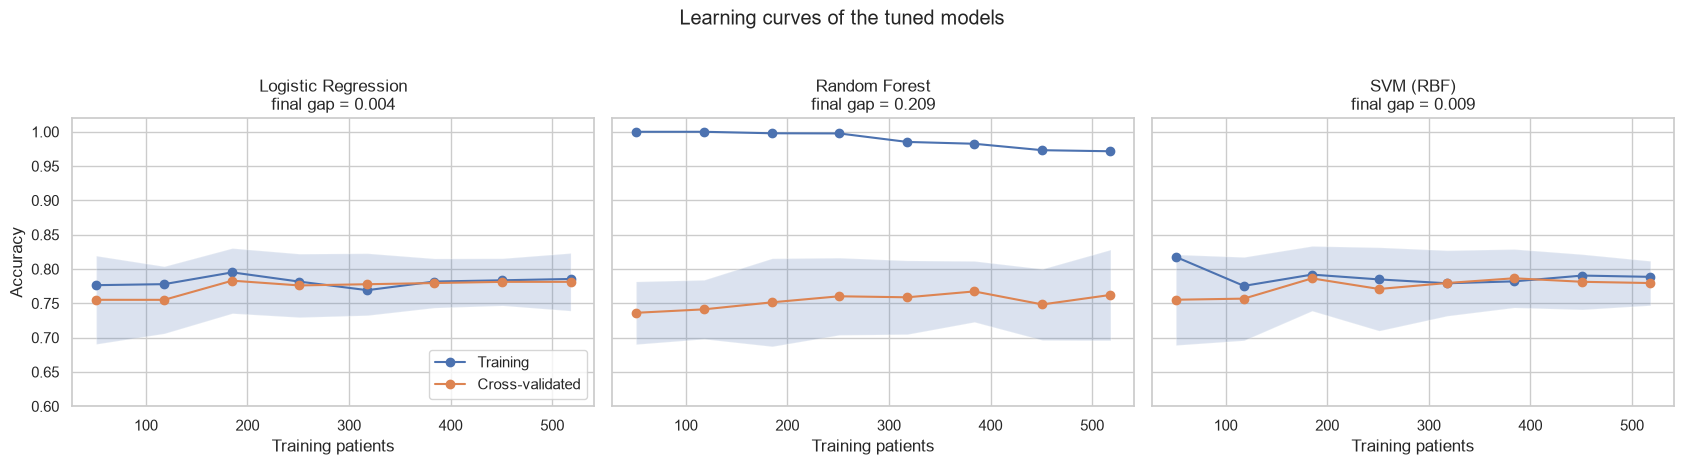

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, (name, est) in zip(axes, best_models.items()):
    sizes, tr, va = learning_curve(est, X_train, y_train, cv=cv, scoring="accuracy",
                                   train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1)
    ax.plot(sizes, tr.mean(1), marker="o", label="Training")
    ax.plot(sizes, va.mean(1), marker="o", label="Cross-validated")
    ax.fill_between(sizes, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=0.2)
    ax.set_title(f"{name}\nfinal gap = {tr.mean(1)[-1] - va.mean(1)[-1]:.3f}")
    ax.set_xlabel("Training patients"); ax.set_ylim(0.6, 1.02)
axes[0].set_ylabel("Accuracy"); axes[0].legend(loc="lower right")
fig.suptitle("Learning curves of the tuned models", y=1.03)
plt.tight_layout(); plt.show()

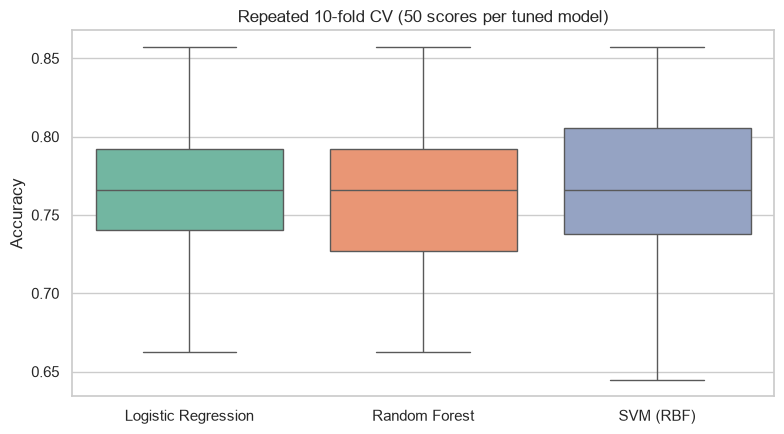

,mean,std,min,max
Logistic Regression,0.765,0.043,0.662,0.857
Random Forest,0.763,0.046,0.662,0.857
SVM (RBF),0.766,0.048,0.645,0.857


,comparison,mean difference,t,p-value,significant at 5%
0,Logistic Regression vs Random Forest,0.0026,0.2155,0.8302,False
1,Logistic Regression vs SVM (RBF),-0.0010,-0.1156,0.9085,False
2,Random Forest vs SVM (RBF),-0.0036,-0.3126,0.7559,False


In [20]:
# Is one model significantly better? (instruction d)
rcv = RepeatedStratifiedKFold(n_splits=CV_FOLDS, n_repeats=5, random_state=RANDOM_STATE)
rep_scores = {name: cross_val_score(est, X, y, cv=rcv, scoring="accuracy", n_jobs=-1)
              for name, est in best_models.items()}

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=pd.DataFrame(rep_scores), ax=ax, palette="Set2")
ax.set_ylabel("Accuracy"); ax.set_title("Repeated 10-fold CV (50 scores per tuned model)")
plt.tight_layout(); plt.show()

summary = pd.DataFrame({n: {"mean": s.mean(), "std": s.std(), "min": s.min(), "max": s.max()}
                        for n, s in rep_scores.items()}).T
display(summary.round(3))

def corrected_t_test(a, b, n_train, n_test):
    # Nadeau & Bengio (2003) corrected resampled t-test for repeated k-fold CV
    d = a - b; k = len(d)
    var = d.var(ddof=1) * (1 / k + n_test / n_train)
    t = d.mean() / np.sqrt(var)
    p = 2 * stats.t.sf(abs(t), df=k - 1)
    return d.mean(), t, p

n_test_fold = len(X) // CV_FOLDS; n_train_fold = len(X) - n_test_fold
names = list(rep_scores)
tests = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        diff, t, p = corrected_t_test(rep_scores[names[i]], rep_scores[names[j]], n_train_fold, n_test_fold)
        tests.append({"comparison": f"{names[i]} vs {names[j]}", "mean difference": diff,
                      "t": t, "p-value": p, "significant at 5%": p < 0.05})
pd.DataFrame(tests).round(4)

### Which features matter, and are they statistically significant? (Based on the instruction of point c)
Three complementary views:

1. **Statistical test per feature:** the Mann-Whitney U test checks whether each feature differs between diabetic and non-diabetic patients. It does not assume normal distributions, which suits skewed features such as Insulin.
2. **Logistic regression with p-values:** on standardised features, each coefficient shows the effect of a one-standard-deviation increase, adjusted for all other features. The **odds ratio** says how many times the odds of diabetes multiply.
3. **Permutation importance:** shuffles one feature at a time on the test set and measures how much the accuracy of each tuned model drops. A large drop means the model relies on that feature.

In [21]:
# (1) Mann-Whitney U test, using observed (non-missing) values only
mw_rows = []
for col in features:
    a = df.loc[df[TARGET] == 1, col].dropna(); b = df.loc[df[TARGET] == 0, col].dropna()
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    mw_rows.append({"feature": col, "median diabetic": a.median(), "median non-diabetic": b.median(),
                    "effect size (r)": 2 * u / (len(a) * len(b)) - 1,  # rank-biserial: 0 = none, 1 = complete separation
                    "p-value": p})
mw = pd.DataFrame(mw_rows).set_index("feature").sort_values("p-value")
mw["significant (p<0.05)"] = mw["p-value"] < 0.05
mw.style.format(precision=3).format({"p-value": "{:.1e}"})

,median diabetic,median non-diabetic,effect size (r),p-value,significant (p<0.05)
feature,,,,,
Glucose,140.000000,107.000000,0.585581,1.3e-40,True
Age,36.000000,27.000000,0.373881,1.1e-17,True
BMI,34.300000,30.100000,0.374072,1.8e-17,True
Insulin,169.500000,102.500000,0.463258,7.5e-14,True
SkinThickness,32.000000,27.000000,0.325023,7.0e-10,True
Pregnancies,4.000000,2.000000,0.239030,3.7e-08,True
DiabetesPedigreeFunction,0.449000,0.336000,0.212403,1.2e-06,True
BloodPressure,74.500000,70.000000,0.215152,1.6e-06,True


In [22]:
# (2) Logistic regression with p-values (statsmodels), fitted on the imputed and standardised training data
prep = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]).fit(X_train)
Xs = pd.DataFrame(prep.transform(X_train), columns=features, index=X_train.index)
logit = sm.Logit(y_train, sm.add_constant(Xs)).fit(disp=False)
coef_table = pd.DataFrame({"coefficient": logit.params, "odds ratio": np.exp(logit.params),
                           "p-value": logit.pvalues}).drop("const").sort_values("p-value")
coef_table["significant (p<0.05)"] = coef_table["p-value"] < 0.05
print(f"Pseudo R-squared: {logit.prsquared:.3f}")
coef_table.style.format(precision=3).format({"p-value": "{:.1e}"})

Pseudo R-squared: 0.297


,coefficient,odds ratio,p-value,significant (p<0.05)
Glucose,1.186651,3.276090,1.9e-17,True
BMI,0.743582,2.103457,2.2e-07,True
Pregnancies,0.451132,1.570089,4.0e-04,True
DiabetesPedigreeFunction,0.215309,1.240244,5.9e-02,False
Age,0.124055,1.132078,3.3e-01,False
BloodPressure,-0.064710,0.937339,6.0e-01,False
SkinThickness,-0.067514,0.934715,6.1e-01,False
Insulin,-0.040310,0.960492,7.4e-01,False


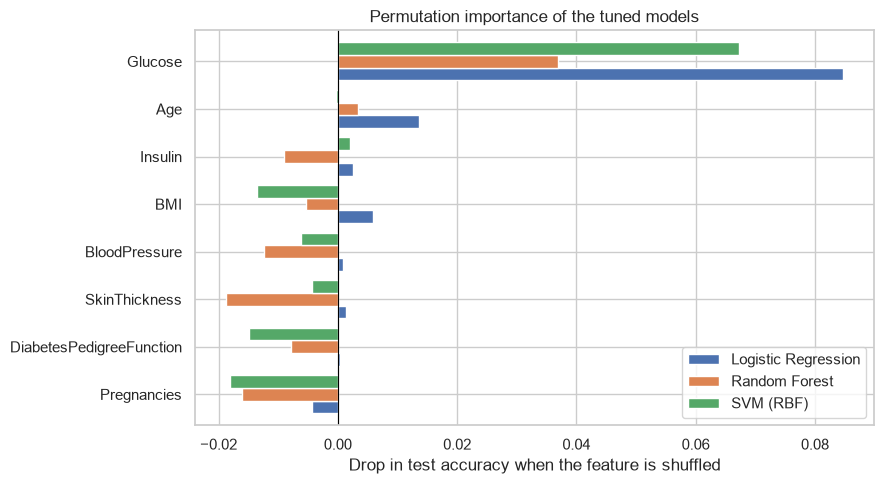

,Logistic Regression,Random Forest,SVM (RBF)
Glucose,0.0847,0.0370,0.0672
Age,0.0135,0.0033,-0.0003
Insulin,0.0026,-0.0090,0.0021
BMI,0.0059,-0.0054,-0.0135
BloodPressure,0.0009,-0.0123,-0.0062
SkinThickness,0.0014,-0.0188,-0.0043
DiabetesPedigreeFunction,0.0003,-0.0078,-0.0149
Pregnancies,-0.0043,-0.0161,-0.0181


In [23]:
# (3) Permutation importance of each tuned model on the test set
perm = {}
for name, est in best_models.items():
    r = permutation_importance(est, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE,
                               scoring="accuracy", n_jobs=-1)
    perm[name] = pd.Series(r.importances_mean, index=features)
perm_df = pd.DataFrame(perm)
order = perm_df.mean(axis=1).sort_values().index

fig, ax = plt.subplots(figsize=(9, 5))
perm_df.loc[order].plot.barh(ax=ax, width=0.8)
ax.axvline(0, c="black", lw=0.8)
ax.set_xlabel("Drop in test accuracy when the feature is shuffled")
ax.set_title("Permutation importance of the tuned models")
plt.tight_layout(); plt.show()
perm_df.loc[order[::-1]].round(4)

In [24]:
lr_best = best_models["Logistic Regression"]
full_acc = cross_val_score(lr_best, X_train, y_train, cv=cv).mean()
ablation = {}
for col in features:
    ablation[col] = full_acc - cross_val_score(lr_best, X_train.drop(columns=col), y_train, cv=cv).mean()
ablation = pd.Series(ablation, name="accuracy lost when removed").sort_values(ascending=False)

top3 = ablation.index[:3].tolist()
top3_acc = cross_val_score(lr_best, X_train[top3], y_train, cv=cv).mean()
print(f"All 8 features:        CV accuracy = {full_acc:.3f}")
print(f"Top 3 only {top3}: CV accuracy = {top3_acc:.3f}")
ablation.round(4).to_frame()

All 8 features:        CV accuracy = 0.781
Top 3 only ['Glucose', 'BMI', 'Pregnancies']: CV accuracy = 0.787


,accuracy lost when removed
Glucose,0.0610
BMI,0.0208
Pregnancies,0.0034
DiabetesPedigreeFunction,0.0034
SkinThickness,0.0017
BloodPressure,0.0000
Insulin,0.0000
Age,-0.0052


## 9. Conclusions

**Recommendation.** Use **Logistic Regression**: equal accuracy, the least overfitting, and coefficients clinicians can interpret. For screening, lower the decision cut-off to about 0.3 so that three quarters of diabetic patients are flagged instead of half.